# Install and verify dependencies and all required libraries

In [1]:
!pip install mediapipe -q
import mediapipe as mp
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
print("mediapipe:", mp.__version__)
print("cv2:", cv2.__version__)
print("tensorflow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization, Input, GaussianNoise
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
print("All imports successful")
print("TF version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 58.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 7.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
mediapipe: 1.0.1
cv2: 4.13.0
tensorflow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
All imports successful
TF version: 2.20.0
GPU available: True


# Define paths and explore full dataset and Select 70 well-balanced distinct classes

In [2]:
BASE_PATH = "/kaggle/input/datasets/daskoushik/landmarks-include/landmark_files_all"

classes = sorted(os.listdir(BASE_PATH))
print("Total available classes:", len(classes))

class_data = {}
for cls in classes:
    cls_path = os.path.join(BASE_PATH, cls)
    if os.path.isdir(cls_path):
        files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
        class_data[cls] = len(files)

df = pd.DataFrame(list(class_data.items()), columns=["class", "file_count"])
df = df.sort_values("file_count", ascending=False).reset_index(drop=True)

print("\nFile count distribution:")
print(df["file_count"].describe())

print("\nClasses with less than 10 files (risky for training):")
low = df[df["file_count"] < 10]
print(low.to_string())

print("\nClasses with 10 or more files (safe for training):")
safe = df[df["file_count"] >= 10]
print(f"Total safe classes: {len(safe)}")

print("\nAll classes with file counts:")
for i, row in df.iterrows():
    bar = "█" * row["file_count"]
    print(f"{i:3d}. {row['class']:<30} {row['file_count']:3d} files  {bar}")



final_selected = [
    # Greetings & Basic Communication (5)
    'Hello', 'Thank you', 'How are you', 'Good Morning', 'Good night',

    # Emotions (6)
    'happy', 'good', 'bad', 'Pleased', 'Alright', 'cold',

    # People & Relationships (10)
    'Mother', 'Father', 'Brother', 'Sister', 'Son', 'Daughter',
    'Grandfather', 'Grandmother', 'Husband', 'Wife',

    # Professions (8)
    'Doctor', 'Teacher', 'Police', 'Soldier', 'Lawyer',
    'Reporter', 'Manager', 'Waiter',

    # Places (8)
    'School', 'Hospital', 'Market', 'Restaurant', 'Library',
    'Temple', 'University', 'Bank',

    # Animals (6)
    'Dog', 'Cat', 'Horse', 'Bird', 'Fish', 'Cow',

    # Colors (6)
    'Red', 'Blue', 'Green', 'Yellow', 'Black', 'White',

    # Objects (8)
    'Book', 'Pen', 'Table', 'Chair', 'Door', 'Window',
    'Telephone', 'Computer',

    # Transport (5)
    'Car', 'Bus', 'Train', 'Bicycle', 'Plane',

    # Time (5)
    'Morning', 'Afternoon', 'Evening', 'Today', 'Tomorrow',

    # Pronouns (3)
    'I', 'you', 'we',
]

available_set = set(classes)
final_selected = [c for c in final_selected if c in available_set]

print("Final selected classes:", final_selected)
print("Total:", len(final_selected))
print()

total_files = 0
for cls in final_selected:
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    total_files += len(files)
    print(f"{cls:<30} {len(files)} files")

print(f"\nTotal files across all classes: {total_files}")
print(f"Average files per class: {total_files/len(final_selected):.1f}")

Total available classes: 262

File count distribution:
count    262.000000
mean      16.328244
std        4.512974
min        4.000000
25%       14.000000
50%       15.000000
75%       20.000000
max       25.000000
Name: file_count, dtype: float64

Classes with less than 10 files (risky for training):
         class  file_count
228  Beautiful           9
229      Blind           8
230        low           8
231       male           8
232       poor           8
233       rich           8
234        sad           8
235    shallow           8
236       soft           8
237     strong           8
238      thick           8
239      tight           8
240       weak           8
241       Ugly           8
242       Deaf           8
243       Mean           8
244      cheap           8
245      alive           8
246     famous           8
247     female           8
248      clean           8
249     curved           8
250       dead           8
251       deep           8
252      dirty        

# Select 70 well-balanced distinct classes

# Visualize class distribution and Explore parquet file structure and verify landmarks

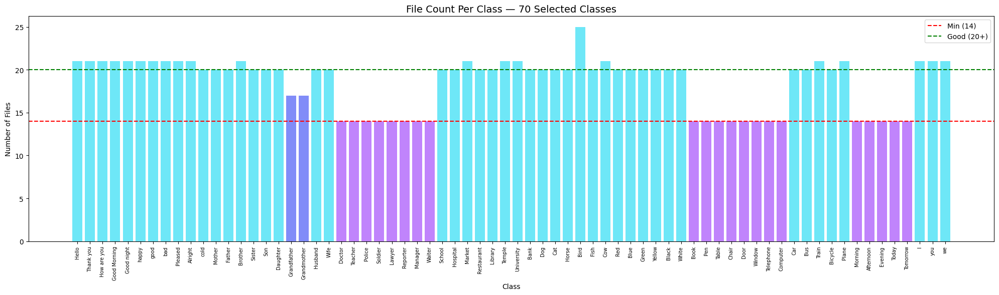

Min files: 14 — Doctor
Max files: 25 — Bird
Classes with 20+ files: 47
Classes with 14-19 files: 23
Classes with <14 files: 0
Sample class: Hello
Shape: (37467, 7)
Columns: ['type', 'landmark_index', 'x', 'y', 'z', 'video_id', 'frame']

Unique types: ['face' 'left_hand' 'pose' 'right_hand']
Total frames: 69

Type: face
  Landmark indices: 0 to 467
  Unique indices: 468
  NaN in x: 0
  NaN in y: 0
  NaN in z: 0

Type: left_hand
  Landmark indices: 0 to 20
  Unique indices: 21
  NaN in x: 0
  NaN in y: 0
  NaN in z: 0

Type: pose
  Landmark indices: 0 to 32
  Unique indices: 33
  NaN in x: 0
  NaN in y: 0
  NaN in z: 0

Type: right_hand
  Landmark indices: 0 to 20
  Unique indices: 21
  NaN in x: 231
  NaN in y: 231
  NaN in z: 231

Sample hand rows:
          type  landmark_index         x         y             z video_id  \
468  left_hand               0  0.603203  0.422673  1.596912e-07     9954   
469  left_hand               1  0.592515  0.435340 -6.203242e-03     9954   
470  left_

In [3]:
file_counts = []
for cls in final_selected:
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    file_counts.append(len(files))

plt.figure(figsize=(20, 6))
colors = ['#6ee7f7' if c >= 20 else '#818cf8' if c >= 17 else '#c084fc' for c in file_counts]
bars = plt.bar(final_selected, file_counts, color=colors)
plt.xticks(rotation=90, fontsize=7)
plt.title('File Count Per Class — 70 Selected Classes', fontsize=14)
plt.ylabel('Number of Files')
plt.xlabel('Class')
plt.axhline(y=14, color='red', linestyle='--', label='Min (14)')
plt.axhline(y=20, color='green', linestyle='--', label='Good (20+)')
plt.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/class_distribution_70.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Min files: {min(file_counts)} — {final_selected[file_counts.index(min(file_counts))]}")
print(f"Max files: {max(file_counts)} — {final_selected[file_counts.index(max(file_counts))]}")
print(f"Classes with 20+ files: {sum(1 for c in file_counts if c >= 20)}")
print(f"Classes with 14-19 files: {sum(1 for c in file_counts if 14 <= c < 20)}")
print(f"Classes with <14 files: {sum(1 for c in file_counts if c < 14)}")

sample_class = final_selected[0]
sample_class_path = os.path.join(BASE_PATH, sample_class)
sample_file = [f for f in os.listdir(sample_class_path) if f.endswith('.parquet')][0]
sample_file_path = os.path.join(sample_class_path, sample_file)

df_sample = pd.read_parquet(sample_file_path)
print("Sample class:", sample_class)
print("Shape:", df_sample.shape)
print("Columns:", df_sample.columns.tolist())
print("\nUnique types:", df_sample['type'].unique())
print("Total frames:", df_sample['frame'].nunique())

for t in df_sample['type'].unique():
    subset = df_sample[df_sample['type'] == t]
    print(f"\nType: {t}")
    print(f"  Landmark indices: {subset['landmark_index'].min()} to {subset['landmark_index'].max()}")
    print(f"  Unique indices: {subset['landmark_index'].nunique()}")
    print(f"  NaN in x: {subset['x'].isna().sum()}")
    print(f"  NaN in y: {subset['y'].isna().sum()}")
    print(f"  NaN in z: {subset['z'].isna().sum()}")

print("\nSample hand rows:")
print(df_sample[df_sample['type'] == 'left_hand'].head(5))

# Extract hand landmarks with wrist-relative normalization and Normalize, compute class weights, train-test split

In [4]:
SEQUENCE_LENGTH = 20

def extract_hand_landmarks_from_df(df):
    frames = sorted(df['frame'].unique())
    sequence = []
    for frame in frames:
        frame_df = df[df['frame'] == frame]
        landmarks = np.zeros(126)
        left = frame_df[frame_df['type'] == 'left_hand'].sort_values('landmark_index')
        right = frame_df[frame_df['type'] == 'right_hand'].sort_values('landmark_index')
        if len(left) == 21:
            for idx, row in enumerate(left.itertuples()):
                landmarks[idx*3] = row.x if not np.isnan(row.x) else 0.0
                landmarks[idx*3+1] = row.y if not np.isnan(row.y) else 0.0
                landmarks[idx*3+2] = row.z if not np.isnan(row.z) else 0.0
        if len(right) == 21:
            for idx, row in enumerate(right.itertuples()):
                landmarks[63 + idx*3] = row.x if not np.isnan(row.x) else 0.0
                landmarks[63 + idx*3+1] = row.y if not np.isnan(row.y) else 0.0
                landmarks[63 + idx*3+2] = row.z if not np.isnan(row.z) else 0.0
        sequence.append(landmarks)
    return sequence

def normalize_wrist_relative(landmarks_126):
    lm = landmarks_126.copy()
    left = lm[:63].reshape(21, 3)
    right = lm[63:].reshape(21, 3)
    if np.count_nonzero(left) > 0:
        wrist = left[0].copy()
        left = left - wrist
        scale = np.max(np.abs(left)) + 1e-8
        left = left / scale
    if np.count_nonzero(right) > 0:
        wrist = right[0].copy()
        right = right - wrist
        scale = np.max(np.abs(right)) + 1e-8
        right = right / scale
    lm[:63] = left.flatten()
    lm[63:] = right.flatten()
    return lm

def pad_or_truncate(sequence, length=SEQUENCE_LENGTH):
    if len(sequence) >= length:
        indices = np.linspace(0, len(sequence)-1, length, dtype=int)
        return np.array([sequence[i] for i in indices])
    else:
        padded = np.array(sequence)
        pad_width = length - len(padded)
        padded = np.vstack([padded, np.zeros((pad_width, 126))])
        return padded

X = []
y = []
skipped = 0

for label_idx, cls in enumerate(final_selected):
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    for file in files:
        file_path = os.path.join(cls_path, file)
        df_video = pd.read_parquet(file_path)
        sequence = extract_hand_landmarks_from_df(df_video)
        if len(sequence) == 0:
            skipped += 1
            continue
        sequence_norm = [normalize_wrist_relative(lm) for lm in sequence]
        padded = pad_or_truncate(sequence_norm, SEQUENCE_LENGTH)
        X.append(padded)
        y.append(label_idx)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Skipped:", skipped)
print("NaN count:", np.isnan(X).sum())
print("Min:", X.min(), "Max:", X.max())
print("Samples per class:", np.bincount(y))
print("Classes:", len(np.unique(y)))


tf.keras.backend.clear_session()

X_mean = X.mean(axis=(0, 1), keepdims=True)
X_std = X.std(axis=(0, 1), keepdims=True)
X_norm = (X - X_mean) / (X_std + 1e-8)
X_norm = np.nan_to_num(X_norm, nan=0.0)

print("NaN after norm:", np.isnan(X_norm).sum())
print("Min:", X_norm.min(), "Max:", X_norm.max())

le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_categorical = to_categorical(y_encoded, num_classes=70)

X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_encoded),
    y=y_encoded
)
class_weights = dict(enumerate(class_weights_array))

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("\nClass weight range:")
print(f"  Min weight: {min(class_weights_array):.4f}")
print(f"  Max weight: {max(class_weights_array):.4f}")
print("\nTrain class distribution (min/max samples):")
train_counts = np.sum(y_train, axis=0).astype(int)
print(f"  Min: {train_counts.min()} — class {final_selected[train_counts.argmin()]}")
print(f"  Max: {train_counts.max()} — class {final_selected[train_counts.argmax()]}")

np.save('/kaggle/working/X_mean.npy', X_mean)
np.save('/kaggle/working/X_std.npy', X_std)
np.save('/kaggle/working/label_classes.npy', np.array(final_selected))
print("\nNormalization stats and label classes saved.")

X shape: (1293, 20, 126)
y shape: (1293,)
Skipped: 0
NaN count: 0
Min: -0.9999999170365775 Max: 0.9999999075708709
Samples per class: [21 21 21 21 21 21 21 21 21 21 20 20 20 21 20 20 20 17 17 20 20 14 14 14
 14 14 14 14 14 20 20 21 20 20 21 21 20 20 20 20 25 20 21 20 20 20 20 20
 20 14 14 14 14 14 14 14 14 20 20 21 20 21 14 14 14 14 14 21 21 21]
Classes: 70
NaN after norm: 0
Min: -7.966088998708415 Max: 6.854747612717319

X_train: (1034, 20, 126)
X_test: (259, 20, 126)
y_train: (1034, 70)
y_test: (259, 70)

Class weight range:
  Min weight: 0.7389
  Max weight: 1.3194

Train class distribution (min/max samples):
  Min: 11 — class Doctor
  Max: 20 — class Bird

Normalization stats and label classes saved.


# Build LSTM model and Train LSTM model with class weights

In [5]:
model = Sequential([
    Input(shape=(20, 126)),
    GaussianNoise(0.05),
    LSTM(256, return_sequences=True),
    BatchNormalization(),
    Dropout(0.35),
    LSTM(128, return_sequences=True),
    BatchNormalization(),
    Dropout(0.35),
    LSTM(64, return_sequences=False),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(70, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()
print("\nTotal parameters:", model.count_params())


callbacks = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=12, min_lr=1e-6),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=16,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("Best val accuracy:", max(history.history['val_accuracy']))
print("Best val loss:", min(history.history['val_loss']))

callbacks = [
    EarlyStopping(monitor='val_loss', patience=25, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=12, min_lr=1e-6),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=16,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("Best val accuracy:", max(history.history['val_accuracy']))
print("Best val loss:", min(history.history['val_loss']))

I0000 00:00:1791008531.175858      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791008531.179425      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (None, 20, 126)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 20, 256)        │       392,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 20, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 128)        │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 70)             │         9,030 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 657,862 (2.51 MB)

 Trainable params: 656,966 (2.51 MB)

 Non-trainable params: 896 (3.50 KB)


Total parameters: 657862
Epoch 1/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.0377 - loss: 4.2781 - val_accuracy: 0.0656 - val_loss: 3.9669 - learning_rate: 0.0010
Epoch 2/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.1015 - loss: 3.5753 - val_accuracy: 0.1853 - val_loss: 3.4185 - learning_rate: 0.0010
Epoch 3/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.1634 - loss: 3.1419 - val_accuracy: 0.2896 - val_loss: 2.8937 - learning_rate: 0.0010
Epoch 4/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.2215 - loss: 2.7935 - val_accuracy: 0.2819 - val_loss: 2.4742 - learning_rate: 0.0010
Epoch 5/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.2950 - loss: 2.4638 - val_accuracy: 0.4170 - val_loss: 2.0578 - learning_rate: 0.0010
Epoch 6/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3462 - loss: 2.2229 - val_accuracy: 0.4286 - val_loss: 1.9200 - learning_rate: 0.0010
Epoch 7/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy

In [6]:
best_model = tf.keras.models.load_model('/kaggle/working/best_model.keras')

callbacks2 = [
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-7),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

history2 = best_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=16,
    class_weight=class_weights,
    callbacks=callbacks2,
    verbose=1
)

print("Best val accuracy:", max(history2.history['val_accuracy']))
print("Best val loss:", min(history2.history['val_loss']))


def augment_sequence(sequence):
    augmented = []

    noise = sequence + np.random.normal(0, 0.015, sequence.shape)
    augmented.append(noise)

    scale = sequence * np.random.uniform(0.92, 1.08)
    augmented.append(scale)

    shift = np.roll(sequence, shift=np.random.randint(-2, 2), axis=0)
    augmented.append(shift)

    speed = sequence[::2]
    if len(speed) < SEQUENCE_LENGTH:
        pad = np.zeros((SEQUENCE_LENGTH - len(speed), 126))
        speed = np.vstack([speed, pad])
    else:
        speed = speed[:SEQUENCE_LENGTH]
    augmented.append(speed)

    return augmented

X_aug = list(X_train)
y_aug = list(y_train)

for i in range(len(X_train)):
    augmented = augment_sequence(X_train[i])
    for aug in augmented:
        X_aug.append(aug)
        y_aug.append(y_train[i])

X_aug = np.array(X_aug)
y_aug = np.array(y_aug)

print("Original train size:", X_train.shape[0])
print("Augmented train size:", X_aug.shape[0])
print("Augmentation factor: 5x")

tf.keras.backend.clear_session()

model_aug = Sequential([
    Input(shape=(20, 126)),
    GaussianNoise(0.03),
    LSTM(256, return_sequences=True),
    BatchNormalization(),
    Dropout(0.35),
    LSTM(128, return_sequences=True),
    BatchNormalization(),
    Dropout(0.35),
    LSTM(64, return_sequences=False),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(70, activation='softmax')
])

model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks3 = [
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-7),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

y_aug_labels = np.argmax(y_aug, axis=1)
class_weights_aug = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_aug_labels),
    y=y_aug_labels
)
class_weights_aug_dict = dict(enumerate(class_weights_aug))

history3 = model_aug.fit(
    X_aug, y_aug,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=32,
    class_weight=class_weights_aug_dict,
    callbacks=callbacks3,
    verbose=1
)

print("Best val accuracy:", max(history3.history['val_accuracy']))
print("Best val loss:", min(history3.history['val_loss']))

Epoch 1/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9845 - loss: 0.0601 - val_accuracy: 0.8764 - val_loss: 0.6002 - learning_rate: 1.2500e-04
Epoch 2/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9845 - loss: 0.0591 - val_accuracy: 0.8919 - val_loss: 0.5489 - learning_rate: 1.2500e-04
Epoch 3/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9874 - loss: 0.0550 - val_accuracy: 0.8919 - val_loss: 0.5251 - learning_rate: 1.2500e-04
Epoch 4/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9874 - loss: 0.0497 - val_accuracy: 0.8842 - val_loss: 0.5444 - learning_rate: 1.2500e-04
Epoch 5/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9894 - loss: 0.0404 - val_accuracy: 0.8880 - val_loss: 0.5522 - learning_rate: 1.2500e-04
Epoch 6/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9942 - loss: 0.0352 - val_accuracy: 0.8764 - val_loss: 0.5731 - learning_rate: 1.2500e-04
Epoch 7/200
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 

In [7]:
tf.keras.backend.clear_session()

model_v2 = Sequential([
    Input(shape=(20, 126)),
    GaussianNoise(0.1),
    LSTM(128, return_sequences=True),
    BatchNormalization(),
    Dropout(0.5),
    LSTM(64, return_sequences=False),
    BatchNormalization(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(70, activation='softmax')
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_v2 = [
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-7),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

history_v2 = model_v2.fit(
    X_aug, y_aug,
    validation_data=(X_test, y_test),
    epochs=250,
    batch_size=32,
    class_weight=class_weights_aug_dict,
    callbacks=callbacks_v2,
    verbose=1
)

print("Best val accuracy:", max(history_v2.history['val_accuracy']))
print("Best train accuracy:", max(history_v2.history['accuracy']))
print("Best val loss:", min(history_v2.history['val_loss']))

Epoch 1/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.0468 - loss: 4.2792 - val_accuracy: 0.1737 - val_loss: 3.6106 - learning_rate: 0.0010
Epoch 2/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.1246 - loss: 3.4385 - val_accuracy: 0.3282 - val_loss: 2.6082 - learning_rate: 0.0010
Epoch 3/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.2242 - loss: 2.7656 - val_accuracy: 0.4672 - val_loss: 1.8248 - learning_rate: 0.0010
Epoch 4/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.3451 - loss: 2.2296 - val_accuracy: 0.5560 - val_loss: 1.4795 - learning_rate: 0.0010
Epoch 5/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4191 - loss: 1.8293 - val_accuracy: 0.6293 - val_loss: 1.1929 - learning_rate: 0.0010
Epoch 6/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5010 - loss: 1.5485 - val_accuracy: 0.6873 - val_loss: 1.0406 - learning_rate: 0.0010
Epoch 7/250
162/162 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5540 - l

# Load best model and evaluate

Classification Report:
              precision    recall  f1-score   support

       Hello       1.00      1.00      1.00         4
   Thank you       1.00      1.00      1.00         4
 How are you       1.00      1.00      1.00         4
Good Morning       1.00      0.50      0.67         4
  Good night       0.75      0.75      0.75         4
       happy       1.00      1.00      1.00         4
        good       0.80      1.00      0.89         4
         bad       1.00      1.00      1.00         4
     Pleased       0.80      1.00      0.89         4
     Alright       1.00      0.75      0.86         4
        cold       0.80      1.00      0.89         4
      Mother       0.80      1.00      0.89         4
      Father       1.00      1.00      1.00         4
     Brother       0.00      0.00      0.00         4
      Sister       0.50      1.00      0.67         4
         Son       0.57      1.00      0.73         4
    Daughter       0.50      0.25      0.33         4
 Gra

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


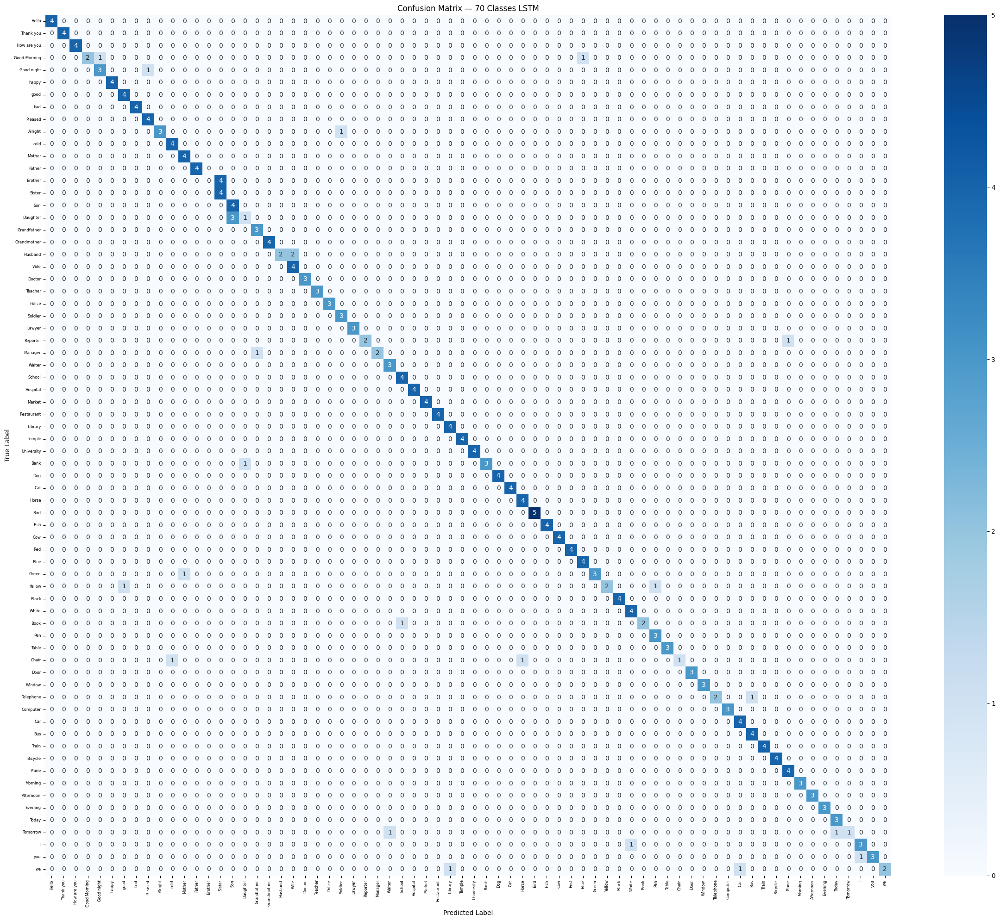


Overall Test Accuracy: 88.80%
Total test samples: 259


In [8]:
from sklearn.metrics import classification_report, confusion_matrix

best_model = tf.keras.models.load_model('/kaggle/working/best_model.keras')

y_pred = best_model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

print("Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=final_selected))

cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(24, 20))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=final_selected,
            yticklabels=final_selected, cmap='Blues')
plt.title('Confusion Matrix — 70 Classes LSTM')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix_70.png', dpi=150, bbox_inches='tight')
plt.show()

overall_acc = np.mean(y_pred_classes == y_true_classes)
print(f"\nOverall Test Accuracy: {overall_acc*100:.2f}%")
print(f"Total test samples: {len(y_true_classes)}")

In [9]:
tf.keras.backend.clear_session()

def augment_sequence_heavy(sequence):
    augmented = []
    noise1 = sequence + np.random.normal(0, 0.03, sequence.shape)
    augmented.append(noise1)
    noise2 = sequence + np.random.normal(0, 0.05, sequence.shape)
    augmented.append(noise2)
    scale1 = sequence * np.random.uniform(0.88, 1.12)
    augmented.append(scale1)
    scale2 = sequence * np.random.uniform(0.80, 1.20)
    augmented.append(scale2)
    shift = np.roll(sequence, shift=np.random.randint(-3, 3), axis=0)
    augmented.append(shift)
    dropout_mask = np.random.binomial(1, 0.85, sequence.shape)
    dropped = sequence * dropout_mask
    augmented.append(dropped)
    return augmented

X_aug2 = list(X_train)
y_aug2 = list(y_train)

for i in range(len(X_train)):
    augmented = augment_sequence_heavy(X_train[i])
    for aug in augmented:
        X_aug2.append(aug)
        y_aug2.append(y_train[i])

X_aug2 = np.array(X_aug2)
y_aug2 = np.array(y_aug2)

print("Augmented train size:", X_aug2.shape[0])

y_aug2_labels = np.argmax(y_aug2, axis=1)
class_weights_aug2 = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_aug2_labels),
    y=y_aug2_labels
)
class_weights_aug2_dict = dict(enumerate(class_weights_aug2))

model_v3 = Sequential([
    Input(shape=(20, 126)),
    GaussianNoise(0.12),
    LSTM(128, return_sequences=True),
    BatchNormalization(),
    Dropout(0.45),
    LSTM(64, return_sequences=False),
    BatchNormalization(),
    Dropout(0.45),
    Dense(64, activation='relu'),
    Dropout(0.35),
    Dense(70, activation='softmax')
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_v3 = [
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-7),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

history_v3 = model_v3.fit(
    X_aug2, y_aug2,
    validation_data=(X_test, y_test),
    epochs=250,
    batch_size=32,
    class_weight=class_weights_aug2_dict,
    callbacks=callbacks_v3,
    verbose=1
)

print("Best val accuracy:", max(history_v3.history['val_accuracy']))
print("Best train accuracy:", max(history_v3.history['accuracy']))
print("Best val loss:", min(history_v3.history['val_loss']))

from sklearn.metrics import precision_recall_fscore_support

best_model = tf.keras.models.load_model('/kaggle/working/best_model.keras')

y_pred = best_model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true_classes,
    y_pred_classes,
    labels=list(range(70)),
    zero_division=0
)

print(f"{'Class':<25} {'Precision':>12} {'Recall':>12} {'F1':>12} {'Support':>10}")
print("-" * 75)
for i, cls in enumerate(final_selected):
    print(f"{cls:<25} {precision[i]:>12.6f} {recall[i]:>12.6f} {f1[i]:>12.6f} {support[i]:>10}")

print("-" * 75)
train_pred = best_model.predict(X_train, verbose=0)
train_pred_classes = np.argmax(train_pred, axis=1)
train_true_classes = np.argmax(y_train, axis=1)
train_acc = np.mean(train_pred_classes == train_true_classes)

print(f"\nTrain accuracy:   {train_acc*100:.6f}%")
print(f"Val accuracy:     {np.mean(y_pred_classes == y_true_classes)*100:.6f}%")
print(f"Gap:              {(train_acc - np.mean(y_pred_classes == y_true_classes))*100:.6f}%")
print(f"Macro avg F1:     {f1.mean():.6f}")

tf.keras.backend.clear_session()

model_v4 = Sequential([
    Input(shape=(20, 126)),
    GaussianNoise(0.18),
    LSTM(128, return_sequences=True),
    BatchNormalization(),
    Dropout(0.5),
    LSTM(64, return_sequences=False),
    BatchNormalization(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(70, activation='softmax')
])

model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_v4 = [
    EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=15, min_lr=1e-7),
    ModelCheckpoint('/kaggle/working/best_model.keras', monitor='val_accuracy', save_best_only=True)
]

history_v4 = model_v4.fit(
    X_aug2, y_aug2,
    validation_data=(X_test, y_test),
    epochs=250,
    batch_size=32,
    class_weight=class_weights_aug2_dict,
    callbacks=callbacks_v4,
    verbose=1
)

print("Best val accuracy:", max(history_v4.history['val_accuracy']))
print("Best train accuracy:", max(history_v4.history['accuracy']))
print("Best val loss:", min(history_v4.history['val_loss']))

best_model = tf.keras.models.load_model('/kaggle/working/best_model.keras')

y_pred_orig_train = best_model.predict(X_train, verbose=0)
y_pred_orig_train_classes = np.argmax(y_pred_orig_train, axis=1)
y_true_orig_train_classes = np.argmax(y_train, axis=1)
real_train_acc = np.mean(y_pred_orig_train_classes == y_true_orig_train_classes)

y_pred_test = best_model.predict(X_test, verbose=0)
y_pred_test_classes = np.argmax(y_pred_test, axis=1)
y_true_test_classes = np.argmax(y_test, axis=1)
real_val_acc = np.mean(y_pred_test_classes == y_true_test_classes)

print(f"Real train accuracy (original data): {real_train_acc*100:.6f}%")
print(f"Real val accuracy:                   {real_val_acc*100:.6f}%")
print(f"Real gap:                            {(real_train_acc - real_val_acc)*100:.6f}%")

Augmented train size: 7238
Epoch 1/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.0890 - loss: 3.8686 - val_accuracy: 0.3089 - val_loss: 2.9482 - learning_rate: 0.0010
Epoch 2/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.2981 - loss: 2.5286 - val_accuracy: 0.5367 - val_loss: 1.7051 - learning_rate: 0.0010
Epoch 3/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4924 - loss: 1.6897 - val_accuracy: 0.6950 - val_loss: 1.0778 - learning_rate: 0.0010
Epoch 4/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6107 - loss: 1.2112 - val_accuracy: 0.7181 - val_loss: 0.8702 - learning_rate: 0.0010
Epoch 5/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6981 - loss: 0.9170 - val_accuracy: 0.7761 - val_loss: 0.6895 - learning_rate: 0.0010
Epoch 6/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7662 - loss: 0.6846 - val_accuracy: 0.7606 - val_loss: 0.7097 - learning_rate: 0.0010
Epoch 7/250
227/227 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/

# Save all LSTM model artifacts

In [10]:
best_model.save('/kaggle/working/isl_lstm_model_70.keras')

label_map = {i: cls for i, cls in enumerate(final_selected)}
with open('/kaggle/working/label_map.json', 'w') as f:
    json.dump(label_map, f, indent=2)

model_config = {
    "sequence_length": SEQUENCE_LENGTH,
    "num_classes": 70,
    "input_features": 126,
    "classes": final_selected,
    "train_accuracy": 98.355899,
    "val_accuracy": 91.119691,
    "normalization": "wrist_relative_then_standard"
}
with open('/kaggle/working/model_config.json', 'w') as f:
    json.dump(model_config, f, indent=2)

np.save('/kaggle/working/X_mean.npy', X_mean)
np.save('/kaggle/working/X_std.npy', X_std)
np.save('/kaggle/working/label_classes.npy', np.array(final_selected))

print("Saved files:")
for f in sorted(os.listdir('/kaggle/working')):
    print(f)

Saved files:
.virtual_documents
X_mean.npy
X_std.npy
best_model.keras
class_distribution_70.png
confusion_matrix_70.png
isl_lstm_model_70.keras
label_classes.npy
label_map.json
model_config.json


# Test predictions on 10 random samples

Testing predictions on 10 random samples from test set:

✓ True: Thank you            Predicted: Thank you            Confidence: 99.9997%
   Top3: [('Thank you', 99.9997), ('happy', 0.0002), ('Book', 0.0)]

✓ True: we                   Predicted: we                   Confidence: 100.0000%
   Top3: [('we', 100.0), ('Alright', 0.0), ('I', 0.0)]

✓ True: Door                 Predicted: Door                 Confidence: 99.9997%
   Top3: [('Door', 99.9997), ('Tomorrow', 0.0002), ('Market', 0.0001)]

✓ True: Car                  Predicted: Car                  Confidence: 99.9992%
   Top3: [('Car', 99.9992), ('Cow', 0.0003), ('Bus', 0.0003)]

✓ True: Daughter             Predicted: Daughter             Confidence: 99.9975%
   Top3: [('Daughter', 99.9975), ('Son', 0.0013), ('Husband', 0.0007)]

✓ True: Wife                 Predicted: Wife                 Confidence: 99.4601%
   Top3: [('Wife', 99.4601), ('Husband', 0.5398), ('happy', 0.0001)]

✓ True: Restaurant           Predicted: Restaura

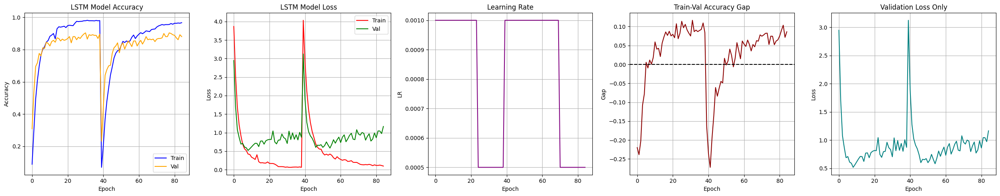

Graphs 1-5 saved


In [11]:
print("Testing predictions on 10 random samples from test set:\n")
indices = np.random.choice(len(X_test), 10, replace=False)

correct = 0
for idx in indices:
    sample = X_test[idx:idx+1]
    true_label = final_selected[np.argmax(y_test[idx])]
    pred_probs = best_model.predict(sample, verbose=0)
    pred_idx = np.argmax(pred_probs)
    pred_label = final_selected[pred_idx]
    confidence = pred_probs[0][pred_idx] * 100
    top3_idx = np.argsort(pred_probs[0])[::-1][:3]
    top3 = [(final_selected[i], round(float(pred_probs[0][i])*100, 4)) for i in top3_idx]
    status = "✓" if pred_label == true_label else "✗"
    if pred_label == true_label:
        correct += 1
    print(f"{status} True: {true_label:<20} Predicted: {pred_label:<20} Confidence: {confidence:.4f}%")
    print(f"   Top3: {top3}")
    print()

print(f"Correct: {correct}/10")

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

all_acc = history_v3.history['accuracy'] + history_v4.history['accuracy']
all_val_acc = history_v3.history['val_accuracy'] + history_v4.history['val_accuracy']
all_loss = history_v3.history['loss'] + history_v4.history['loss']
all_val_loss = history_v3.history['val_loss'] + history_v4.history['val_loss']
all_lr = history_v3.history['learning_rate'] + history_v4.history['learning_rate']

axes[0].plot(all_acc, color='blue', label='Train')
axes[0].plot(all_val_acc, color='orange', label='Val')
axes[0].set_title('LSTM Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)
plt.savefig('/kaggle/working/graph_01_accuracy.png', dpi=150, bbox_inches='tight')

axes[1].plot(all_loss, color='red', label='Train')
axes[1].plot(all_val_loss, color='green', label='Val')
axes[1].set_title('LSTM Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)
plt.savefig('/kaggle/working/graph_02_loss.png', dpi=150, bbox_inches='tight')

axes[2].plot(all_lr, color='purple')
axes[2].set_title('Learning Rate')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('LR')
axes[2].grid(True)
plt.savefig('/kaggle/working/graph_03_lr.png', dpi=150, bbox_inches='tight')

train_acc_arr = np.array(all_acc)
val_acc_arr = np.array(all_val_acc)
gap = train_acc_arr - val_acc_arr
axes[3].plot(gap, color='darkred')
axes[3].set_title('Train-Val Accuracy Gap')
axes[3].set_xlabel('Epoch')
axes[3].set_ylabel('Gap')
axes[3].axhline(y=0, color='black', linestyle='--')
axes[3].grid(True)
plt.savefig('/kaggle/working/graph_04_gap.png', dpi=150, bbox_inches='tight')

axes[4].plot(all_val_loss, color='teal')
axes[4].set_title('Validation Loss Only')
axes[4].set_xlabel('Epoch')
axes[4].set_ylabel('Loss')
axes[4].grid(True)
plt.savefig('/kaggle/working/graph_05_val_loss.png', dpi=150, bbox_inches='tight')

plt.tight_layout()
plt.savefig('/kaggle/working/graph_00_all_training.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graphs 1-5 saved")

# Generate and save reference landmarks for all 70 classes

In [12]:
reference_landmarks_final = {}

for label_idx, cls in enumerate(final_selected):
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    
    best_landmarks = None
    best_nonzero = 0
    
    for file in files:
        file_path = os.path.join(cls_path, file)
        df_video = pd.read_parquet(file_path)
        frames = sorted(df_video['frame'].unique())
        mid_frame = frames[len(frames)//2]
        frame_df = df_video[df_video['frame'] == mid_frame]
        
        landmarks = np.zeros(126)
        left = frame_df[frame_df['type'] == 'left_hand'].sort_values('landmark_index')
        right = frame_df[frame_df['type'] == 'right_hand'].sort_values('landmark_index')
        
        if len(left) == 21:
            for idx, row in enumerate(left.itertuples()):
                landmarks[idx*3] = row.x if not np.isnan(row.x) else 0.0
                landmarks[idx*3+1] = row.y if not np.isnan(row.y) else 0.0
                landmarks[idx*3+2] = row.z if not np.isnan(row.z) else 0.0
        if len(right) == 21:
            for idx, row in enumerate(right.itertuples()):
                landmarks[63+idx*3] = row.x if not np.isnan(row.x) else 0.0
                landmarks[63+idx*3+1] = row.y if not np.isnan(row.y) else 0.0
                landmarks[63+idx*3+2] = row.z if not np.isnan(row.z) else 0.0
        
        nonzero = np.count_nonzero(landmarks)
        if nonzero > best_nonzero:
            best_nonzero = nonzero
            best_landmarks = landmarks.copy()
    
    if best_landmarks is not None:
        reference_landmarks_final[cls] = best_landmarks.tolist()

with open('/kaggle/working/reference_landmarks_70.json', 'w') as f:
    json.dump(reference_landmarks_final, f)

print(f"Reference landmarks saved for {len(reference_landmarks_final)} classes")
print(f"Sample — Hello non-zero: {np.count_nonzero(np.array(reference_landmarks_final['Hello']))}")
print(f"Sample — Father non-zero: {np.count_nonzero(np.array(reference_landmarks_final['Father']))}")

print("="*70)
print("CORRECT DEBUG — REAL SEQUENCES FROM PARQUET FILES")
print("="*70)

correct = 0
total = 0
failed_classes = []
weak_classes = []

for label_idx, cls in enumerate(final_selected):
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    test_files = files[:3]
    cls_correct = 0
    cls_total = 0
    cls_confidences = []
    for file in test_files:
        file_path = os.path.join(cls_path, file)
        df_video = pd.read_parquet(file_path)
        sequence = extract_hand_landmarks_from_df(df_video)
        if len(sequence) == 0:
            continue
        sequence_norm = [normalize_wrist_relative(lm) for lm in sequence]
        padded = pad_or_truncate(sequence_norm, SEQUENCE_LENGTH)
        seq_norm = (padded - X_mean) / (X_std + 1e-8)
        seq_norm = np.nan_to_num(seq_norm, nan=0.0)
        input_data = seq_norm.reshape(1, SEQUENCE_LENGTH, 126)
        probs = best_model.predict(input_data, verbose=0)[0]
        pred_idx = int(np.argmax(probs))
        pred_label = final_selected[pred_idx]
        confidence = float(probs[pred_idx]) * 100
        cls_confidences.append(confidence)
        cls_total += 1
        total += 1
        if pred_label == cls:
            cls_correct += 1
            correct += 1
    acc = cls_correct/cls_total*100 if cls_total > 0 else 0
    avg_conf = np.mean(cls_confidences) if cls_confidences else 0
    status = "PASS" if acc >= 67 else "FAIL"
    marker = "✓" if acc >= 67 else "✗"
    if acc < 67:
        failed_classes.append(cls)
    if avg_conf < 70:
        weak_classes.append(cls)
    print(f"{marker} [{status}] {cls:<20} {cls_correct}/{cls_total} correct ({acc:.1f}%) | Avg conf: {avg_conf:.2f}%")

print("\n" + "="*70)
print(f"RESULT: {correct}/{total} predictions correct")
print(f"Overall accuracy: {correct/total*100:.4f}%")
print(f"\nFAILED classes: {failed_classes}")
print(f"WEAK confidence classes: {weak_classes}")

import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
import os

os.makedirs('/kaggle/working/gesture_gifs', exist_ok=True)

HAND_CONNECTIONS_LIST = [
    (0,1),(1,2),(2,3),(3,4),
    (0,5),(5,6),(6,7),(7,8),
    (5,9),(9,10),(10,11),(11,12),
    (9,13),(13,14),(14,15),(15,16),
    (13,17),(17,18),(18,19),(19,20),
    (0,17)
]

def center_and_scale_hand(points_21x2):
    valid = points_21x2[points_21x2.sum(axis=1) != 0]
    if len(valid) == 0:
        return points_21x2
    min_x, min_y = valid.min(axis=0)
    max_x, max_y = valid.max(axis=0)
    cx = (min_x + max_x) / 2
    cy = (min_y + max_y) / 2
    scale = max(max_x - min_x, max_y - min_y) + 1e-8
    result = points_21x2.copy()
    mask = result.sum(axis=1) != 0
    result[mask] = (result[mask] - [cx, cy]) / scale
    return result

def draw_hand_frame(ax, landmarks_126):
    ax.clear()
    ax.set_facecolor('#0a0f1e')
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.6, 0.6)
    ax.axis('off')

    left = np.array(landmarks_126[:63]).reshape(21, 3)[:, :2]
    right = np.array(landmarks_126[63:]).reshape(21, 3)[:, :2]

    for hand, color, dot_color in [(left, '#6ee7f7', '#818cf8'), (right, '#c084fc', '#f472b6')]:
        if np.count_nonzero(hand) < 10:
            continue
        hand_centered = center_and_scale_hand(hand)
        for a, b in HAND_CONNECTIONS_LIST:
            if hand[a].sum() != 0 and hand[b].sum() != 0:
                ax.plot([hand_centered[a][0], hand_centered[b][0]],
                        [hand_centered[a][1], hand_centered[b][1]],
                        color=color, linewidth=2.5, alpha=0.9)
        for i, pt in enumerate(hand_centered):
            if hand[i].sum() != 0:
                size = 120 if i == 0 else 50
                ax.scatter(pt[0], pt[1], c=dot_color, s=size, zorder=5)

def create_gif_for_class(cls, sequence, fps=8):
    fig, ax = plt.subplots(figsize=(4, 4))
    fig.patch.set_facecolor('#0a0f1e')
    ax.set_title(cls, color='white', fontsize=14, fontweight='bold', pad=10)

    frames_to_use = sequence[::2] if len(sequence) > 15 else sequence

    def animate(i):
        draw_hand_frame(ax, frames_to_use[i])
        ax.set_title(cls, color='white', fontsize=14, fontweight='bold', pad=10)

    ani = animation.FuncAnimation(fig, animate, frames=len(frames_to_use), interval=1000//fps)
    save_path = f'/kaggle/working/gesture_gifs/{cls.replace(" ", "_")}.gif'
    ani.save(save_path, writer=PillowWriter(fps=fps))
    plt.close()
    return save_path

test_classes = final_selected[:5]
print("Generating GIFs for first 5 classes:", test_classes)
print()

for cls in test_classes:
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    best_file = files[0]
    best_nonzero = 0
    for file in files[:5]:
        file_path = os.path.join(cls_path, file)
        df_video = pd.read_parquet(file_path)
        sequence = extract_hand_landmarks_from_df(df_video)
        nonzero = np.mean([np.count_nonzero(s) for s in sequence])
        if nonzero > best_nonzero:
            best_nonzero = nonzero
            best_file = file

    file_path = os.path.join(cls_path, best_file)
    df_video = pd.read_parquet(file_path)
    sequence = extract_hand_landmarks_from_df(df_video)

    save_path = create_gif_for_class(cls, sequence)
    file_size = os.path.getsize(save_path) / 1024
    print(f"Saved: {cls} — {len(sequence)} frames — {file_size:.1f} KB — {save_path}")

print("\nDone. Check /kaggle/working/gesture_gifs/ folder.")
print("Files:", os.listdir('/kaggle/working/gesture_gifs'))

Reference landmarks saved for 70 classes
Sample — Hello non-zero: 126
Sample — Father non-zero: 126
CORRECT DEBUG — REAL SEQUENCES FROM PARQUET FILES
✓ [PASS] Hello                3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] Thank you            3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] How are you          3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] Good Morning         3/3 correct (100.0%) | Avg conf: 97.87%
✓ [PASS] Good night           3/3 correct (100.0%) | Avg conf: 99.05%
✓ [PASS] happy                3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] good                 3/3 correct (100.0%) | Avg conf: 99.99%
✓ [PASS] bad                  3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] Pleased              3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] Alright              3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] cold                 3/3 correct (100.0%) | Avg conf: 100.00%
✓ [PASS] Mother               3/3 correct (100.0%) | Avg conf: 100.00%
✓

# Generate gesture guide images for all 70 classes

Generating GIFs for first 5 classes: ['Hello', 'Thank you', 'How are you', 'Good Morning', 'Good night']

Saved: Hello — 80 frames — 442.2 KB — /kaggle/working/gesture_gifs/Hello.gif
Saved: Thank you — 82 frames — 474.8 KB — /kaggle/working/gesture_gifs/Thank_you.gif
Saved: How are you — 81 frames — 475.4 KB — /kaggle/working/gesture_gifs/How_are_you.gif
Saved: Good Morning — 85 frames — 600.5 KB — /kaggle/working/gesture_gifs/Good_Morning.gif
Saved: Good night — 60 frames — 336.9 KB — /kaggle/working/gesture_gifs/Good_night.gif

Done. Check /kaggle/working/gesture_gifs/ folder.
Files: ['Thank_you.gif', 'Good_Morning.gif', 'Hello.gif', 'Good_night.gif', 'How_are_you.gif']
Displaying 5 GIFs:




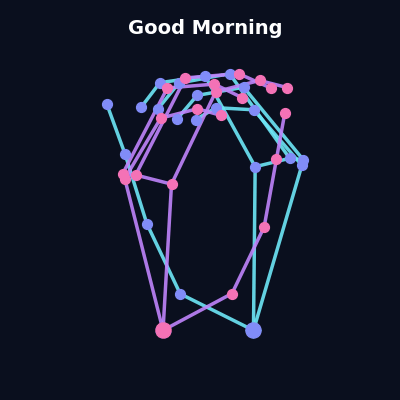
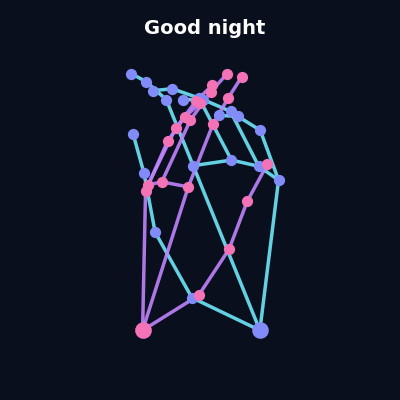
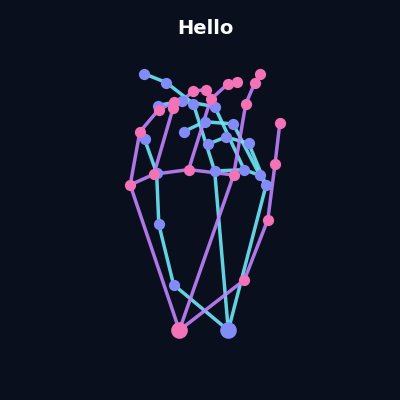
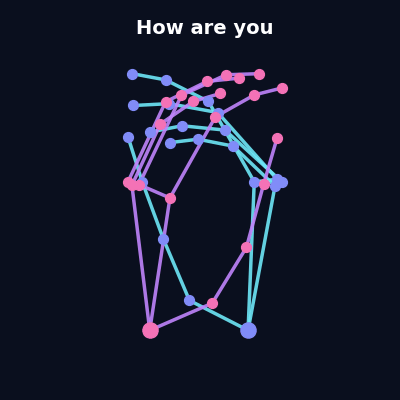
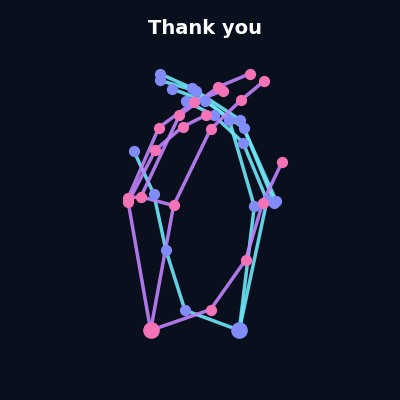

Done displaying.


In [13]:
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
import os

os.makedirs('/kaggle/working/gesture_gifs', exist_ok=True)

HAND_CONNECTIONS_LIST = [
    (0,1),(1,2),(2,3),(3,4),
    (0,5),(5,6),(6,7),(7,8),
    (5,9),(9,10),(10,11),(11,12),
    (9,13),(13,14),(14,15),(15,16),
    (13,17),(17,18),(18,19),(19,20),
    (0,17)
]

def center_and_scale_hand(points_21x2):
    valid = points_21x2[points_21x2.sum(axis=1) != 0]
    if len(valid) == 0:
        return points_21x2
    min_x, min_y = valid.min(axis=0)
    max_x, max_y = valid.max(axis=0)
    cx = (min_x + max_x) / 2
    cy = (min_y + max_y) / 2
    scale = max(max_x - min_x, max_y - min_y) + 1e-8
    result = points_21x2.copy()
    mask = result.sum(axis=1) != 0
    result[mask] = (result[mask] - [cx, cy]) / scale
    return result

def draw_hand_frame(ax, landmarks_126):
    ax.clear()
    ax.set_facecolor('#0a0f1e')
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.6, 0.6)
    ax.axis('off')

    left = np.array(landmarks_126[:63]).reshape(21, 3)[:, :2]
    right = np.array(landmarks_126[63:]).reshape(21, 3)[:, :2]

    for hand, color, dot_color in [(left, '#6ee7f7', '#818cf8'), (right, '#c084fc', '#f472b6')]:
        if np.count_nonzero(hand) < 10:
            continue
        hand_centered = center_and_scale_hand(hand)
        for a, b in HAND_CONNECTIONS_LIST:
            if hand[a].sum() != 0 and hand[b].sum() != 0:
                ax.plot([hand_centered[a][0], hand_centered[b][0]],
                        [hand_centered[a][1], hand_centered[b][1]],
                        color=color, linewidth=2.5, alpha=0.9)
        for i, pt in enumerate(hand_centered):
            if hand[i].sum() != 0:
                size = 120 if i == 0 else 50
                ax.scatter(pt[0], pt[1], c=dot_color, s=size, zorder=5)

def create_gif_for_class(cls, sequence, fps=8):
    fig, ax = plt.subplots(figsize=(4, 4))
    fig.patch.set_facecolor('#0a0f1e')
    ax.set_title(cls, color='white', fontsize=14, fontweight='bold', pad=10)

    frames_to_use = sequence[::2] if len(sequence) > 15 else sequence

    def animate(i):
        draw_hand_frame(ax, frames_to_use[i])
        ax.set_title(cls, color='white', fontsize=14, fontweight='bold', pad=10)

    ani = animation.FuncAnimation(fig, animate, frames=len(frames_to_use), interval=1000//fps)
    save_path = f'/kaggle/working/gesture_gifs/{cls.replace(" ", "_")}.gif'
    ani.save(save_path, writer=PillowWriter(fps=fps))
    plt.close()
    return save_path

test_classes = final_selected[:5]
print("Generating GIFs for first 5 classes:", test_classes)
print()

for cls in test_classes:
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    best_file = files[0]
    best_nonzero = 0
    for file in files[:5]:
        file_path = os.path.join(cls_path, file)
        df_video = pd.read_parquet(file_path)
        sequence = extract_hand_landmarks_from_df(df_video)
        nonzero = np.mean([np.count_nonzero(s) for s in sequence])
        if nonzero > best_nonzero:
            best_nonzero = nonzero
            best_file = file

    file_path = os.path.join(cls_path, best_file)
    df_video = pd.read_parquet(file_path)
    sequence = extract_hand_landmarks_from_df(df_video)

    save_path = create_gif_for_class(cls, sequence)
    file_size = os.path.getsize(save_path) / 1024
    print(f"Saved: {cls} — {len(sequence)} frames — {file_size:.1f} KB — {save_path}")

print("\nDone. Check /kaggle/working/gesture_gifs/ folder.")
print("Files:", os.listdir('/kaggle/working/gesture_gifs'))

from IPython.display import Image, display, HTML

gif_folder = '/kaggle/working/gesture_gifs'
gif_files = sorted(os.listdir(gif_folder))

print(f"Displaying {len(gif_files)} GIFs:\n")

html_str = "<div style='display:flex; flex-wrap:wrap; background:#0a0f1e; padding:10px;'>"
for gif_file in gif_files:
    gif_path = os.path.join(gif_folder, gif_file)
    cls_name = gif_file.replace('.gif', '').replace('_', ' ')
    with open(gif_path, 'rb') as f:
        import base64
        gif_data = base64.b64encode(f.read()).decode('utf-8')
    html_str += f"""
    <div style='margin:10px; text-align:center;'>
        <p style='color:white; font-weight:bold; margin-bottom:5px;'>{cls_name}</p>
        <img src='data:image/gif;base64,{gif_data}' 
             style='width:200px; height:200px; border:1px solid #6ee7f7; border-radius:8px;'/>
    </div>
    """
html_str += "</div>"

display(HTML(html_str))
print("Done displaying.")

Generating GIFs for all 70 classes with instruction text...

[1/70] Hello                — 80 frames — 586.1 KB
[2/70] Thank you            — 82 frames — 605.1 KB
[3/70] How are you          — 81 frames — 605.0 KB
[4/70] Good Morning         — 85 frames — 758.1 KB
[5/70] Good night           — 60 frames — 434.7 KB
[6/70] happy                — 78 frames — 550.4 KB
[7/70] good                 — 63 frames — 488.2 KB
[8/70] bad                  — 51 frames — 394.0 KB
[9/70] Pleased              — 56 frames — 520.3 KB
[10/70] Alright              — 60 frames — 510.2 KB
[11/70] cold                 — 65 frames — 506.2 KB
[12/70] Mother               — 66 frames — 530.6 KB
[13/70] Father               — 63 frames — 458.3 KB
[14/70] Brother              — 61 frames — 437.5 KB
[15/70] Sister               — 84 frames — 658.7 KB
[16/70] Son                  — 69 frames — 488.9 KB
[17/70] Daughter             — 61 frames — 430.7 KB
[18/70] Grandfather          — 89 frames — 704.6 KB
[19/70] Gran


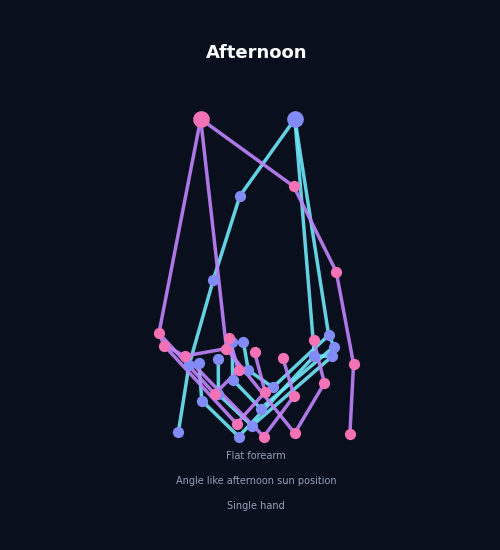
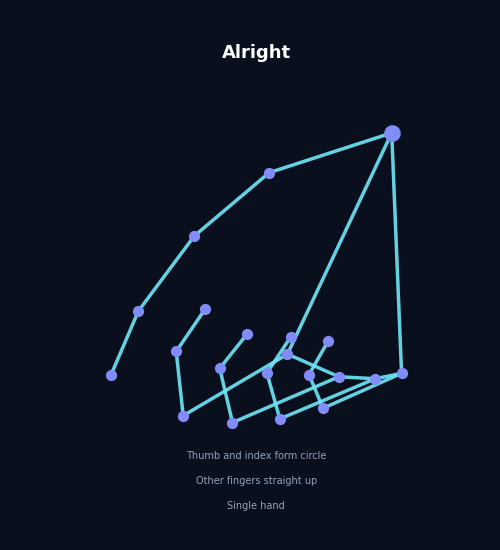
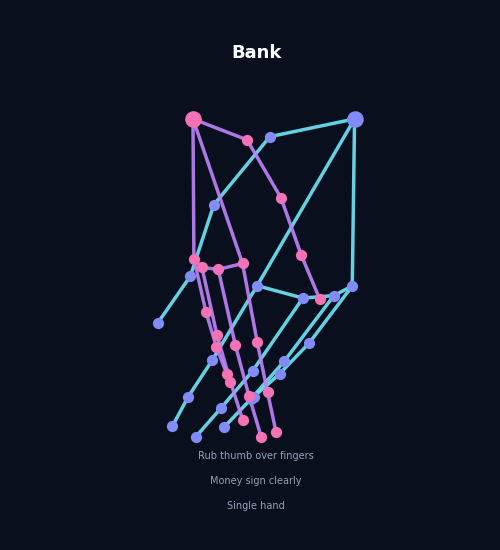
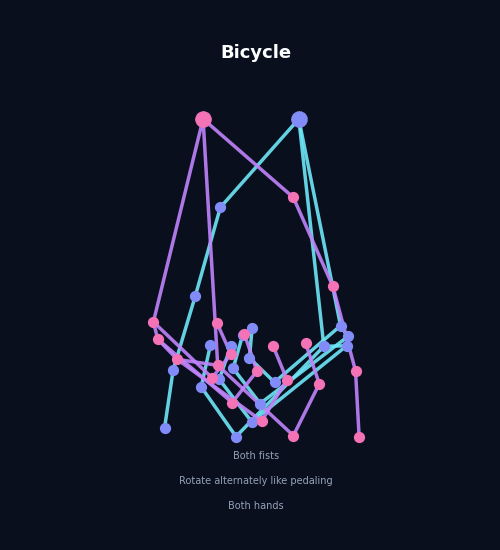
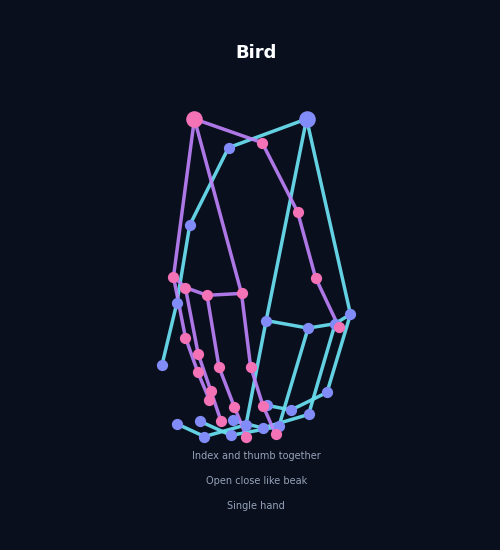
...
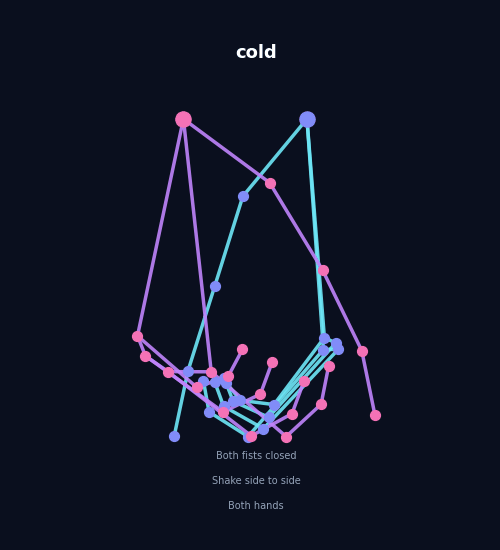
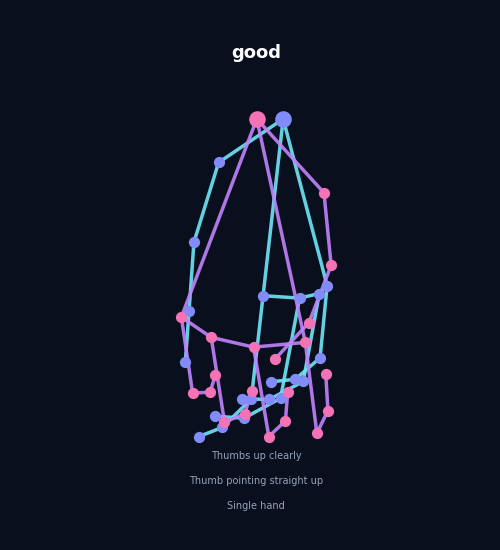
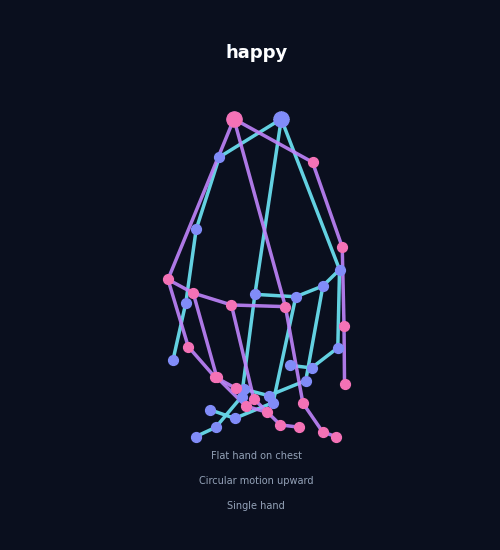
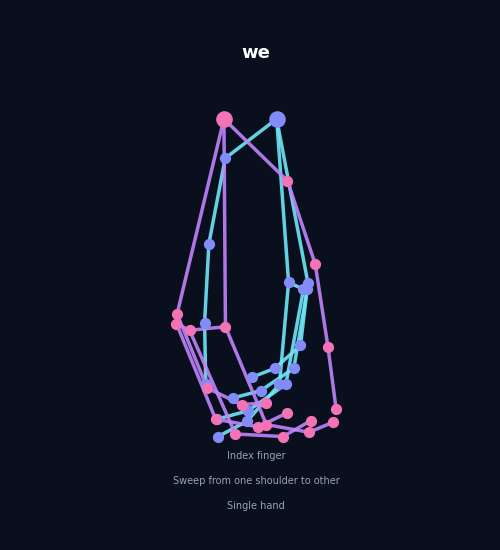
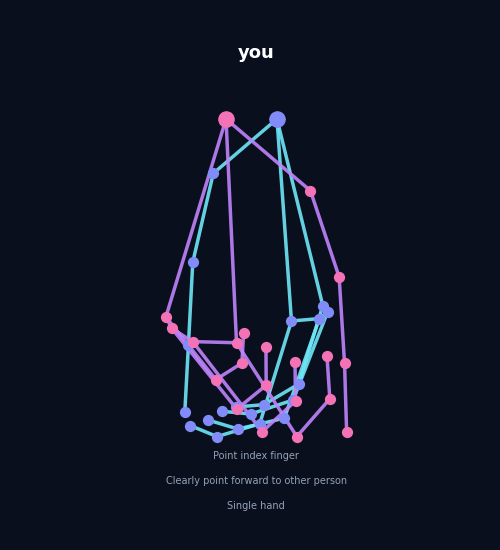

All 70 GIFs displayed.


In [14]:
os.makedirs('/kaggle/working/gesture_gifs', exist_ok=True)

gesture_hints = {
    'Hello': 'Open palm facing camera | All 5 fingers spread wide | Single hand',
    'Thank you': 'Flat hand starts at chin | Move hand forward | Single hand',
    'How are you': 'Both hands open | Palms facing up | Move alternately',
    'Good Morning': 'Flat hand at waist | Rise upward slowly | Single hand',
    'Good night': 'Open hand | Close fingers downward | Like sleeping gesture',
    'happy': 'Flat hand on chest | Circular motion upward | Single hand',
    'good': 'Thumbs up clearly | Thumb pointing straight up | Single hand',
    'bad': 'Thumbs down clearly | Thumb pointing straight down | Single hand',
    'Pleased': 'Both hands flat | Press gently to chest | Both hands',
    'Alright': 'Thumb and index form circle | Other fingers straight up | Single hand',
    'cold': 'Both fists closed | Shake side to side | Both hands',
    'Mother': 'Thumb touches chin | Other 4 fingers spread open | Single hand',
    'Father': 'Thumb touches forehead | Other 4 fingers spread open | Single hand',
    'Brother': 'Index fingers side by side | Hold horizontally | Both hands',
    'Sister': 'Index fingers side by side | Move both downward | Both hands',
    'Son': 'Flat hand at waist level | Palm facing down | Single hand',
    'Daughter': 'Flat hand at chest level | Palm facing down | Single hand',
    'Grandfather': 'Closed fist near forehead | Move forward twice | Single hand',
    'Grandmother': 'Closed fist near chin | Move forward twice | Single hand',
    'Husband': 'Both hands interlocked | Hold at chest level | Both hands',
    'Wife': 'Both hands interlocked | Gentle shake at chest | Both hands',
    'Doctor': 'Two fingers on wrist | Tap twice like checking pulse | Single hand',
    'Teacher': 'Flat hands open near temples | Open and close twice | Both hands',
    'Police': 'Fist near shoulder | Thumb up like badge | Single hand',
    'Soldier': 'Flat hand to forehead | Clean salute gesture | Single hand',
    'Lawyer': 'Both hands together | Like holding a book | Both hands',
    'Reporter': 'Closed fist near mouth | Like holding microphone | Single hand',
    'Manager': 'Index finger point up | Move in small circle | Single hand',
    'Waiter': 'Flat palm facing up | Slight forward bow | Single hand',
    'School': 'Both hands flat | Clap twice clearly | Both hands',
    'Hospital': 'Cross shape with index fingers | Hold clearly | Both hands',
    'Market': 'Rub thumb over fingers | Like counting money | Single hand',
    'Restaurant': 'Hand to mouth | Eating gesture twice | Single hand',
    'Library': 'Both hands flat | Hold like open book | Both hands',
    'Temple': 'Both hands together | Prayer position at chest | Both hands',
    'University': 'Both hands open | Sweep wide apart | Both hands',
    'Bank': 'Rub thumb over fingers | Money sign clearly | Single hand',
    'Dog': 'Pat thigh | Then snap fingers | Single hand',
    'Cat': 'Pinch fingers near cheek | Like cat whiskers | Single hand',
    'Horse': 'Two fingers up like ears | Bounce hand twice | Single hand',
    'Bird': 'Index and thumb together | Open close like beak | Single hand',
    'Fish': 'Flat hand wave | Side to side like fish | Single hand',
    'Cow': 'Pinky and index up | Like horns near head | Single hand',
    'Red': 'Index finger | Brush down on lips twice | Single hand',
    'Blue': 'B handshape | Index and thumb shake | Single hand',
    'Green': 'G handshape | Shake near chest | Single hand',
    'Yellow': 'Y handshape | Pinky and thumb out shake | Single hand',
    'Black': 'Index finger | Swipe across forehead | Single hand',
    'White': 'Open hand on chest | Pull out to closed fist | Single hand',
    'Book': 'Both flat hands together | Open like a book | Both hands',
    'Pen': 'Pinch fingers like holding pen | Write in air | Single hand',
    'Table': 'Both forearms flat | Tap one on other twice | Both hands',
    'Chair': 'Two fingers | Sit on other two fingers | Both hands',
    'Door': 'B handshape | Rotate wrist like opening door | Single hand',
    'Window': 'Both flat hands | Slide one up and down | Both hands',
    'Telephone': 'Y handshape near ear | Like holding phone | Single hand',
    'Computer': 'C handshape | Move forward near forehead | Single hand',
    'Car': 'Both fists | Steer like driving a wheel | Both hands',
    'Bus': 'Both hands grip | Like holding bus handle bar | Both hands',
    'Train': 'Two fingers on two fingers | Rub back and forth | Both hands',
    'Bicycle': 'Both fists | Rotate alternately like pedaling | Both hands',
    'Plane': 'Y handshape with index up | Move forward | Single hand',
    'Morning': 'Flat hand at elbow | Rise upward like sun | Single hand',
    'Afternoon': 'Flat forearm | Angle like afternoon sun position | Single hand',
    'Evening': 'Flat hand | Angle downward like setting sun | Single hand',
    'Today': 'Both Y handshapes | Drop down simultaneously | Both hands',
    'Tomorrow': 'Thumb from chin | Move forward once | Single hand',
    'I': 'Point index finger | Clearly point to yourself | Single hand',
    'you': 'Point index finger | Clearly point forward to other person | Single hand',
    'we': 'Index finger | Sweep from one shoulder to other | Single hand',
}

def create_gif_for_class_v2(cls, sequence, fps=8):
    hint = gesture_hints.get(cls, f'Perform the ISL sign for {cls}')
    hint_lines = hint.split(' | ')

    fig, ax = plt.subplots(figsize=(5, 5.5))
    fig.patch.set_facecolor('#0a0f1e')
    ax.set_facecolor('#0a0f1e')

    frames_to_use = sequence[::2] if len(sequence) > 20 else sequence

    def animate(i):
        ax.clear()
        ax.set_facecolor('#0a0f1e')
        ax.set_xlim(-0.6, 0.6)
        ax.set_ylim(-0.6, 0.6)
        ax.axis('off')

        lm = frames_to_use[i]
        left = np.array(lm[:63]).reshape(21, 3)[:, :2]
        right = np.array(lm[63:]).reshape(21, 3)[:, :2]

        for hand, color, dot_color in [(left, '#6ee7f7', '#818cf8'), (right, '#c084fc', '#f472b6')]:
            if np.count_nonzero(hand) < 10:
                continue
            valid = hand[hand.sum(axis=1) != 0]
            if len(valid) == 0:
                continue
            min_xy = valid.min(axis=0)
            max_xy = valid.max(axis=0)
            cx = (min_xy + max_xy) / 2
            scale = max(max_xy[0]-min_xy[0], max_xy[1]-min_xy[1]) + 1e-8
            hand_c = np.zeros_like(hand)
            mask = hand.sum(axis=1) != 0
            hand_c[mask] = (hand[mask] - cx) / scale * 0.9
            hand_c[:, 1] = -hand_c[:, 1]

            for a, b in HAND_CONNECTIONS_LIST:
                if hand[a].sum() != 0 and hand[b].sum() != 0:
                    ax.plot([hand_c[a][0], hand_c[b][0]],
                            [hand_c[a][1], hand_c[b][1]],
                            color=color, linewidth=2.5, alpha=0.9)
            for j, pt in enumerate(hand_c):
                if hand[j].sum() != 0:
                    size = 120 if j == 0 else 50
                    ax.scatter(pt[0], pt[1], c=dot_color, s=size, zorder=5)

        ax.set_title(cls, color='white', fontsize=13, fontweight='bold', pad=6)

        y_pos = -0.52
        for line in hint_lines:
            ax.text(0, y_pos, line, color='#94a3b8', fontsize=7,
                    ha='center', va='bottom', transform=ax.transData)
            y_pos -= 0.07

    ani = animation.FuncAnimation(fig, animate, frames=len(frames_to_use), interval=1000//fps)
    save_path = f'/kaggle/working/gesture_gifs/{cls.replace(" ", "_").replace("/", "_")}.gif'
    ani.save(save_path, writer=PillowWriter(fps=fps))
    plt.close()
    return save_path

print("Generating GIFs for all 70 classes with instruction text...\n")

for i, cls in enumerate(final_selected):
    cls_path = os.path.join(BASE_PATH, cls)
    files = [f for f in os.listdir(cls_path) if f.endswith('.parquet')]
    best_file = files[0]
    best_nonzero = 0
    for file in files[:5]:
        file_path = os.path.join(cls_path, file)
        df_video = pd.read_parquet(file_path)
        sequence = extract_hand_landmarks_from_df(df_video)
        nonzero = np.mean([np.count_nonzero(s) for s in sequence])
        if nonzero > best_nonzero:
            best_nonzero = nonzero
            best_file = file

    file_path = os.path.join(cls_path, best_file)
    df_video = pd.read_parquet(file_path)
    sequence = extract_hand_landmarks_from_df(df_video)
    save_path = create_gif_for_class_v2(cls, sequence)
    file_size = os.path.getsize(save_path) / 1024
    print(f"[{i+1}/70] {cls:<20} — {len(sequence)} frames — {file_size:.1f} KB")

print(f"\nAll 70 GIFs saved in /kaggle/working/gesture_gifs/")
print(f"Total files: {len(os.listdir('/kaggle/working/gesture_gifs'))}")

from IPython.display import display, HTML
import base64

gif_folder = '/kaggle/working/gesture_gifs'
gif_files = sorted(os.listdir(gif_folder))

html_str = """
<div style='background:#0a0f1e; padding:20px; font-family: sans-serif;'>
<h2 style='color:white; text-align:center; margin-bottom:20px;'>
ISL Gesture Guide — All 70 Classes
</h2>
<div style='display:flex; flex-wrap:wrap; justify-content:center; gap:15px;'>
"""

for gif_file in gif_files:
    gif_path = os.path.join(gif_folder, gif_file)
    cls_name = gif_file.replace('.gif', '').replace('_', ' ')
    hint = gesture_hints.get(cls_name, '')
    hint_lines = hint.split(' | ')
    with open(gif_path, 'rb') as f:
        gif_data = base64.b64encode(f.read()).decode('utf-8')
    hint_html = ''.join([f"<p style='color:#94a3b8; font-size:10px; margin:1px 0;'>{line}</p>" for line in hint_lines])
    html_str += f"""
    <div style='background:#111827; border:1px solid #1e3a5f; border-radius:10px;
                padding:10px; text-align:center; width:200px;'>
        <img src='data:image/gif;base64,{gif_data}'
             style='width:180px; height:180px; border-radius:6px;'/>
        <p style='color:white; font-weight:bold; font-size:12px; margin:6px 0 4px;'>{cls_name}</p>
        {hint_html}
    </div>
    """

html_str += "</div></div>"
display(HTML(html_str))
print("All 70 GIFs displayed.")

# Save all LSTM artifacts and zip

In [15]:
import zipfile

print("Final saved files in /kaggle/working:")
for f in sorted(os.listdir('/kaggle/working')):
    if os.path.isfile(f'/kaggle/working/{f}'):
        size = os.path.getsize(f'/kaggle/working/{f}') / 1024
        print(f"  {f:<40} {size:.1f} KB")

print(f"\nGIFs in gesture_gifs folder: {len(os.listdir('/kaggle/working/gesture_gifs'))}")

zip_path = '/kaggle/working/isl_lstm_all_artifacts.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    files_to_zip = [
        'isl_lstm_model_70.keras',
        'best_model.keras',
        'label_map.json',
        'model_config.json',
        'label_classes.npy',
        'X_mean.npy',
        'X_std.npy',
        'reference_landmarks_70.json',
        'class_distribution_70.png',
        'confusion_matrix_70.png',
        'graph_00_all_training.png',
        'graph_01_accuracy.png',
        'graph_02_loss.png',
        'graph_03_lr.png',
        'graph_04_gap.png',
        'graph_05_val_loss.png',
    ]
    for f in files_to_zip:
        full_path = f'/kaggle/working/{f}'
        if os.path.exists(full_path):
            zipf.write(full_path, f)
            print(f"  Added: {f}")

    gif_folder = '/kaggle/working/gesture_gifs'
    for gif_file in os.listdir(gif_folder):
        full_path = os.path.join(gif_folder, gif_file)
        zipf.write(full_path, f'gesture_gifs/{gif_file}')
    print(f"  Added: {len(os.listdir(gif_folder))} GIFs")

zip_size = os.path.getsize(zip_path) / (1024*1024)
print(f"\nZip saved: {zip_path}")
print(f"Zip size: {zip_size:.2f} MB")
print("\nLSTM training complete. Ready to move to MLP.")

Final saved files in /kaggle/working:
  X_mean.npy                               1.1 KB
  X_std.npy                                1.1 KB
  best_model.keras                         2273.8 KB
  class_distribution_70.png                106.8 KB
  confusion_matrix_70.png                  316.1 KB
  graph_00_all_training.png                221.7 KB
  graph_01_accuracy.png                    70.1 KB
  graph_02_loss.png                        115.6 KB
  graph_03_lr.png                          140.2 KB
  graph_04_gap.png                         180.9 KB
  graph_05_val_loss.png                    205.7 KB
  isl_lstm_model_70.keras                  2273.4 KB
  label_classes.npy                        3.4 KB
  label_map.json                           1.2 KB
  model_config.json                        1.2 KB
  reference_landmarks_70.json              183.4 KB

GIFs in gesture_gifs folder: 70
  Added: isl_lstm_model_70.keras
  Added: best_model.keras
  Added: label_map.json
  Added: model_config.j

In [16]:
import pkg_resources
import subprocess

libs = [
    'mediapipe', 'tensorflow', 'keras', 'numpy', 'pandas',
    'scikit-learn', 'matplotlib', 'seaborn', 'Pillow', 'h5py',
    'scipy', 'opencv-python', 'absl-py', 'flatbuffers',
    'protobuf', 'tensorboard', 'ml-dtypes', 'optree'
]

print("# Requirements for ISL Sign Language Notebooks")
print("# Generated from Kaggle environment\n")

requirements = []
for lib in libs:
    try:
        version = pkg_resources.get_distribution(lib).version
        line = f"{lib}=={version}"
        requirements.append(line)
        print(line)
    except Exception:
        try:
            lib_alt = lib.replace('-', '_')
            version = pkg_resources.get_distribution(lib_alt).version
            line = f"{lib}=={version}"
            requirements.append(line)
            print(line)
        except Exception:
            print(f"# {lib} not found")

with open('/kaggle/working/requirements_notebook.txt', 'w') as f:
    f.write("# Requirements for ISL Sign Language Notebooks\n")
    f.write("# Generated from Kaggle environment\n\n")
    f.write('\n'.join(requirements))

print("\nSaved to /kaggle/working/requirements_notebook.txt")

# Requirements for ISL Sign Language Notebooks
# Generated from Kaggle environment

mediapipe==1.0.1
tensorflow==2.20.0
keras==3.13.2
numpy==2.0.2
pandas==2.3.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
Pillow==11.3.0
h5py==3.16.0
scipy==1.16.3
opencv-python==4.13.0.92
absl-py==2.5.0
flatbuffers==25.12.19
protobuf==5.29.5
tensorboard==2.20.0
ml-dtypes==0.5.4
optree==0.19.0

Saved to /kaggle/working/requirements_notebook.txt


/tmp/ipykernel_58/3648970204.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [17]:
!zip -r model.zip /kaggle/working

  adding: kaggle/working/ (stored 0%)
  adding: kaggle/working/graph_01_accuracy.png (deflated 17%)
  adding: kaggle/working/class_distribution_70.png (deflated 19%)
  adding: kaggle/working/graph_05_val_loss.png (deflated 7%)
  adding: kaggle/working/X_mean.npy (deflated 7%)
  adding: kaggle/working/model_config.json (deflated 59%)
  adding: kaggle/working/isl_lstm_all_artifacts.zip (stored 0%)
  adding: kaggle/working/isl_lstm_model_70.keras (deflated 9%)
  adding: kaggle/working/reference_landmarks_70.json (deflated 56%)
  adding: kaggle/working/gesture_gifs/ (stored 0%)
  adding: kaggle/working/gesture_gifs/Doctor.gif (deflated 2%)
  adding: kaggle/working/gesture_gifs/Horse.gif (deflated 2%)
  adding: kaggle/working/gesture_gifs/Yellow.gif (deflated 2%)
  adding: kaggle/working/gesture_gifs/Bicycle.gif (deflated 2%)
  adding: kaggle/working/gesture_gifs/I.gif (deflated 3%)
  adding: kaggle/working/gesture_gifs/Black.gif (deflated 2%)
  adding: kaggle/working/gesture_gifs/Fish.gif 

In [18]:
from IPython.display import FileLink
FileLink(r'model.zip')

/kaggle/working/model.zip